In [ ]:
from numpy.distutils.system_info import lapack_src_info

from utils.hydraharp import HydraHarp
import numpy as np
import matplotlib.pyplot as plt
import sys
import socket
import time
import Components as comp

hh = HydraHarp()

if socket.gethostname() == "ph-photonbec5":
    sys.path.append(r"D:/Control/PythonPackages/")
laser = comp.Toptica_Laser()

def measure_histogram(hh, seconds=20, channel=0):
    """Acquire a fresh HydraHarp histogram."""

    if not 0 <= channel < hh.channels:
        raise ValueError("Invalid input channel")

    hh.start(seconds)

    try:
        deadline = time.monotonic() + seconds + 10

        while not hh.complete():
            if time.monotonic() > deadline:
                raise TimeoutError(
                    "HydraHarp acquisition timed out"
                )

            time.sleep(0.05)

    finally:
        result = hh.stop_read()

    counts = np.asarray(
        result["histograms"][channel],
        dtype=np.uint32
    )

    delay_ns = (
        np.arange(counts.size)
        * hh.settings["resolution_ps"]
        / 1000
    )

    return delay_ns, counts, result


<ipython-input-1-b15df99c93ff>:1: DeprecationWarning: 

  `numpy.distutils` is deprecated since NumPy 1.23.0, as a result
  of the deprecation of `distutils` itself. It will be removed for
  Python >= 3.12. For older Python versions it will remain present.
  It is recommended to use `setuptools < 60.0` for those Python versions.
  For more details, see:
    https://numpy.org/devdocs/reference/distutils_status_migration.html 


  from numpy.distutils.system_info import lapack_src_info


Starting scan for 0.0376 W
Scanned histogram for 0.0376 W


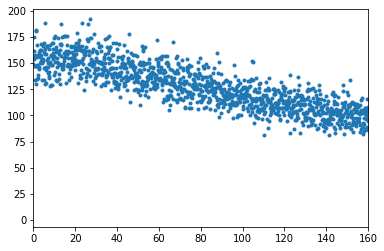

Starting scan for 0.0378 W
Scanned histogram for 0.0378 W


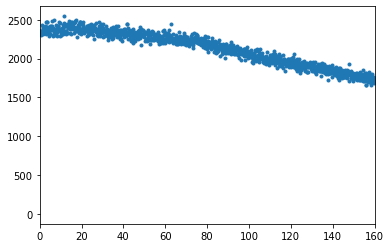

Starting scan for 0.038 W
Scanned histogram for 0.038 W


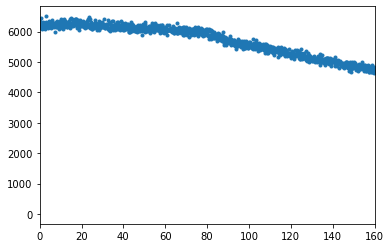

Starting scan for 0.0382 W
Scanned histogram for 0.0382 W


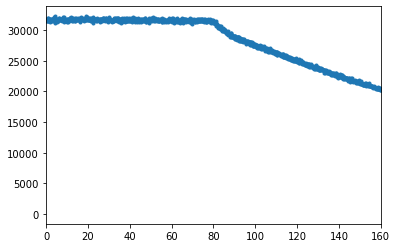

Starting scan for 0.0384 W
Scanned histogram for 0.0384 W


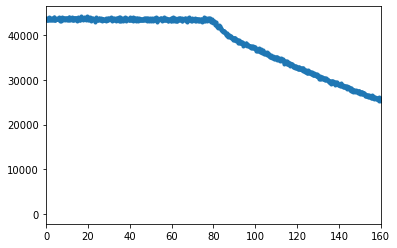

Starting scan for 0.038599999999999995 W
Scanned histogram for 0.038599999999999995 W


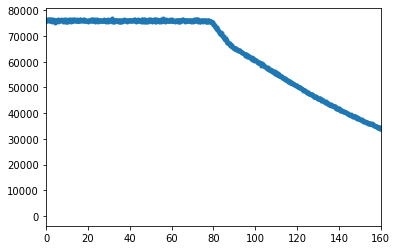

Starting scan for 0.038799999999999994 W
Scanned histogram for 0.038799999999999994 W


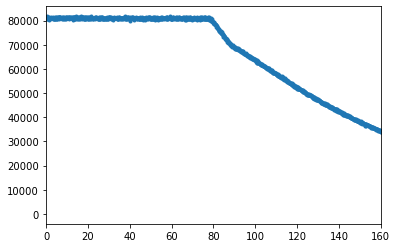

Starting scan for 0.03899999999999999 W
Scanned histogram for 0.03899999999999999 W


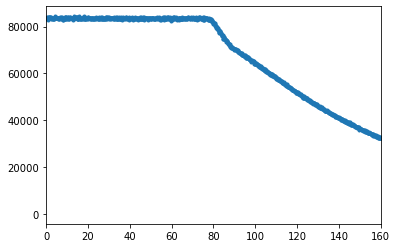

Starting scan for 0.03919999999999999 W
Scanned histogram for 0.03919999999999999 W


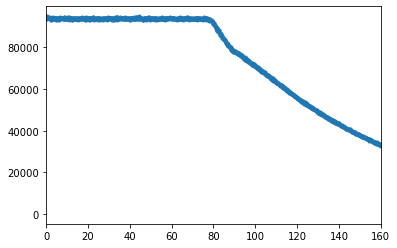

Starting scan for 0.03939999999999999 W
Scanned histogram for 0.03939999999999999 W


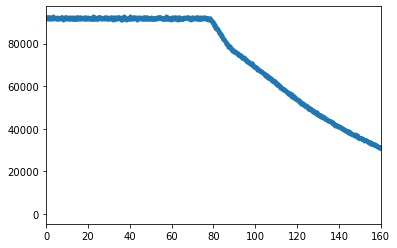

Starting scan for 0.03959999999999999 W
Scanned histogram for 0.03959999999999999 W


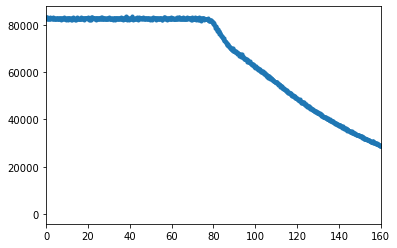

Starting scan for 0.03979999999999999 W
Scanned histogram for 0.03979999999999999 W


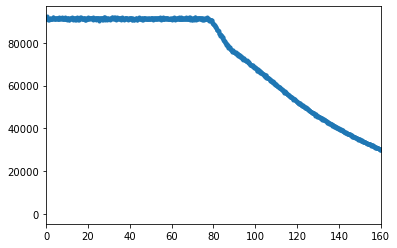

In [3]:
laser_powers = np.arange(0.0376,0.040,0.0002)

for power in laser_powers:
    laser.set(power=power)
    print(f"Starting scan for {power} W")
    delay_ns, counts, _ = measure_histogram(hh, seconds=20, channel=0)
    print(f"Scanned histogram for {power} W")
    plt.plot(delay_ns, counts, '.')
    plt.xlim(0, 160)
    plt.show()

    np.savetxt(
        f"g2_measurements_951nm/ND4/{np.round(power, 4)}W_g2.csv",
        np.column_stack((delay_ns, counts)),
        delimiter=",",
        header="delay_ns, counts",
        comments=""
    )



In [8]:
hh.close()